In [57]:
from functools import partial
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.patches import Patch

from helper import get_amino_acid_sequence, summarise_activations
from interplm.embedders import ESM
from interplm.sae.inference import load_sae_from_hf


# Hydropathy reference for testing feature 8893

**Kyte–Doolittle hydropathy scale.** Higher values indicate more hydrophobic character; lower values indicate more hydrophilic character on this scale. Values are unnormalized.

Source: [ExPASy ProtScale — Kyte & Doolittle](https://web.expasy.org/protscale/pscale/Hphob.Doolittle.html), citing Kyte J. & Doolittle R.F., *J. Mol. Biol.* **157**, 105–132 (1982).

| Amino acid | One-letter code | Hydropathy |
|---|:---:|---:|
| Alanine | A | 1.8 |
| Arginine | R | -4.5 |
| Asparagine | N | -3.5 |
| Aspartic acid | D | -3.5 |
| Cysteine | C | 2.5 |
| Glutamine | Q | -3.5 |
| Glutamic acid | E | -3.5 |
| Glycine | G | -0.4 |
| Histidine | H | -3.2 |
| Isoleucine | I | 4.5 |
| Leucine | L | 3.8 |
| Lysine | K | -3.9 |
| Methionine | M | 1.9 |
| Phenylalanine | F | 2.8 |
| Proline | P | -1.6 |
| Serine | S | -0.8 |
| Threonine | T | -0.7 |
| Tryptophan | W | -0.9 |
| Tyrosine | Y | -1.3 |
| Valine | V | 4.2 |

In [58]:
# GPT 6.1 Sol High Effort implemented the function below to calculate hydropathy and aided my understanding of hydropathy

**Calculation:** centered sliding-window arithmetic mean, default **19 residues**, with equal weights and no normalization. [ProtScale documentation](https://web.expasy.org/protscale/protscale-doc.html) recommends 19 or 21 residues for highlighting hydrophobic membrane-spanning stretches. An odd window gives each mean an exact central residue; try smaller odd windows to inspect shorter stretches.

The function below returns one row per residue with **1-based positions**, the individual residue value (`hydropathy`), and the local mean (`window_mean`). Positions without a complete centered window are `NaN` (the first/last 9 residues for window 19). For a whole-sequence mean, use `profile['hydropathy'].mean()`; local scores retain the stretches that this average hides. 

Note that Hydropathy alone does not establish membrane topology.

**Formula used by the function:**

$$
H_w(i) = \frac{1}{w}\sum_{j=-k}^{k} h(a_{i+j}),
\qquad k = \frac{w-1}{2}.
$$

Here $a_i$ is the residue at 1-based position $i$, $h(a_i)$ is its Kyte–Doolittle lookup value, $w$ is the odd window size, and $H_w(i)$ is the returned `window_mean`. Each residue in the window has equal weight. For the default $w=19$, this averages residue $i$ and its 9 neighbours on each side. For a sequence of length $L$, the formula is evaluated only where $k+1 \leq i \leq L-k$; other positions are `NaN`.


In [59]:
# Unnormalized Kyte–Doolittle values, as listed by ExPASy ProtScale:
# https://web.expasy.org/protscale/pscale/Hphob.Doolittle.html
KYTE_DOOLITTLE = {
    'A': 1.8, 'R': -4.5, 'N': -3.5, 'D': -3.5, 'C': 2.5,
    'Q': -3.5, 'E': -3.5, 'G': -0.4, 'H': -3.2, 'I': 4.5,
    'L': 3.8, 'K': -3.9, 'M': 1.9, 'F': 2.8, 'P': -1.6,
    'S': -0.8, 'T': -0.7, 'W': -0.9, 'Y': -1.3, 'V': 4.2,
}


def calculate_hydropathy(sequence: str, window: int = 19) -> pd.DataFrame:
    """Return per-residue Kyte–Doolittle values and centered window means.

    Accepts a plain one-letter sequence; lowercase and whitespace are
    normalized. Rejects empty sequences and symbols outside the 20-residue
    scale (including unknown/ambiguous residues, gaps and stop markers).
    The window must be a positive odd integer no longer than the sequence.
    Positions are 1-based after whitespace removal. Incomplete windows at
    the termini are NaN; individual residue values remain available there.
    """
    if not isinstance(sequence, str):
        raise TypeError('sequence must be a plain one-letter amino acid string.')
    sequence = ''.join(sequence.split()).upper()
    if not sequence:
        raise ValueError('sequence must contain at least one amino acid.')
    unsupported = sorted(set(sequence) - KYTE_DOOLITTLE.keys())
    if unsupported:
        raise ValueError(f'No Kyte–Doolittle value for: {unsupported}')
    if isinstance(window, bool) or not isinstance(window, int):
        raise TypeError('window must be a positive odd integer.')
    if window < 1 or window % 2 == 0:
        raise ValueError('window must be a positive odd integer.')
    if window > len(sequence):
        raise ValueError('window exceeds sequence length; choose a smaller odd window.')

    profile = pd.DataFrame({
        'position': range(1, len(sequence) + 1),
        'residue': list(sequence),
        'hydropathy': [KYTE_DOOLITTLE[aa] for aa in sequence],
    })
    profile['window_mean'] = profile['hydropathy'].rolling(
        window=window, center=True, min_periods=window
    ).mean()
    return profile

## Hydropathy along the sequence

`plot_hydropathy(sequence)` draws a wrapped colour bar with one letter per residue and 1-based sequence positions. **Blue = more hydrophilic; orange = more hydrophobic; near-white = around zero.** All plots use the same −4.5 to +4.5 scale so colours are comparable across proteins.

Colours show the **19-residue sliding mean** by default; use `window=1` for individual residue values. Grey marks incomplete terminal windows. Set `residues_per_line` to control wrapping (default 60). The function returns the Matplotlib figure and sequence axes for saving or further annotation.


In [60]:
def plot_hydropathy(
    sequence: str,
    window: int = 19,
    residues_per_line: int = 60,
    title: str | None = None,
):
    """Plot a wrapped residue strip coloured by Kyte–Doolittle hydropathy.

    Uses calculate_hydropathy for sequence validation and centered means.
    window=1 gives individual residue values. Incomplete windows are grey.
    Colours always span -4.5 to +4.5, with zero at the neutral midpoint.
    Returns (figure, list_of_sequence_axes); call figure.savefig(...) to export.
    """
    if isinstance(residues_per_line, bool) or not isinstance(residues_per_line, int):
        raise TypeError('residues_per_line must be a positive integer.')
    if residues_per_line < 1:
        raise ValueError('residues_per_line must be a positive integer.')
    profile = calculate_hydropathy(sequence, window=window)
    columns = min(residues_per_line, len(profile))
    rows = (len(profile) + columns - 1) // columns

    cmap = LinearSegmentedColormap.from_list(
        'kyte_doolittle', ['#2166ac', '#f7f7f7', '#b35806']
    )
    cmap.set_bad('#d9dde3')
    norm = Normalize(vmin=-4.5, vmax=4.5)
    mode = 'Individual residue values' if window == 1 else f'{window}-residue centered mean'
    fig = plt.figure(figsize=(max(8, columns * 0.21 + 1.6), rows * 0.8 + 1.9))
    grid = fig.add_gridspec(
        rows + 1, 1, height_ratios=[1] * rows + [0.3], hspace=1.15,
        left=0.06, right=0.94, top=1 - 0.75 / fig.get_figheight(),
        bottom=0.85 / fig.get_figheight(),
    )
    fig.suptitle(f'{title or "Sequence hydropathy"} — {mode}', y=0.98, fontsize=13)
    axes = []
    for row in range(rows):
        start = row * columns
        segment = profile.iloc[start:start + columns]
        values = segment['window_mean'].to_numpy()
        ax = fig.add_subplot(grid[row])
        strip = ax.imshow(
            np.ma.masked_invalid(values[np.newaxis, :]),
            cmap=cmap, norm=norm, interpolation='nearest', aspect='auto',
            extent=(0, len(segment), 0, 1),
        )
        for offset, (residue, value) in enumerate(zip(segment['residue'], values)):
            rgba = cmap(norm(value)) if np.isfinite(value) else cmap.get_bad()
            luminance = np.dot(rgba[:3], [0.2126, 0.7152, 0.0722])
            ax.text(
                offset + 0.5, 0.5, residue, ha='center', va='center',
                fontfamily='monospace', fontsize=10,
                color='white' if luminance < 0.48 else '#17212b',
            )
        # Keep cell widths fixed, including on a partially filled final row.
        ax.set_xlim(0, columns)
        ax.set_ylim(0, 1)
        ax.set_yticks([])
        ticks = [p for p in segment['position'] if p % 10 == 0]
        ax.set_xticks([p - start - 0.5 for p in ticks], labels=ticks)
        ax.tick_params(axis='x', length=0, labelsize=8, colors='#536170', pad=3)
        for spine in ax.spines.values():
            spine.set_visible(False)
        ax.text(-0.6, 0.5, str(start + 1), ha='right', va='center', fontsize=9)
        ax.text(len(segment) + 0.6, 0.5, str(start + len(segment)),
                ha='left', va='center', fontsize=9)
        axes.append(ax)

    colourbar = fig.colorbar(strip, cax=fig.add_subplot(grid[-1]), orientation='horizontal')
    colourbar.set_ticks([-4.5, -3, -1.5, 0, 1.5, 3, 4.5])
    colourbar.set_label('Kyte–Doolittle hydropathy: hydrophilic (−) → hydrophobic (+)', fontsize=10)
    colourbar.outline.set_visible(False)
    if profile['window_mean'].isna().any():
        fig.legend(
            handles=[Patch(facecolor=cmap.get_bad(), label='Incomplete centered window')],
            loc='lower right', bbox_to_anchor=(0.94, 0), frameon=False, fontsize=9,
        )
    return fig, axes


In [61]:
# I used GPT 6.1 Sol High Effort to automate the fetching of these proteins to test the current hypothesis

## Protein panel: does feature 8893 follow hydrophobic stretches?

**Selected 22 November 2026: 15 reviewed proteins, 97–760 residues.** Five single-pass helical proteins, five multipass helical proteins, and five diagnostic controls (including a membrane β-barrel). Contexts span humans, bacteria, yeast, plants, a virus and an insect. Several repeat notebook 04 for continuity; this is an exploratory panel, not an independent validation set. No new feature-8893 activations were screened for selection.

**Scores:** calculated by executing this notebook's `calculate_hydropathy(sequence, window=19)` on the complete canonical UniProt sequences, including signal peptides. **Peak H19** is the largest centered 19-residue mean, rounded to 3 decimals; parentheses give its **19-residue window**, not a membrane annotation. All coordinates are **1-based, inclusive**; the earliest tied maximum is listed. The annotations and biological context come from the linked UniProt entries; scores and experimental rationales are our calculations/interpretations.

| Group | Protein / UniProt source | Biological context; reason to include | aa | Reference topology / processing | Peak H19 (window) |
|---|---|---|---:|---|---|
| Single-pass | **TFRC** — [P02786](https://www.uniprot.org/uniprotkb/P02786/entry) | Human iron uptake; large extracellular domain provides within-protein contrast. | 760 | 1 helix: 68–88 (type II) | **2.426** (66–84) |
| Single-pass | **CD8 alpha** — [P01732](https://www.uniprot.org/uniprotkb/P01732/entry) | Human T-cell co-receptor; compare a cleaved signal with the retained anchor. | 235 | Signal 1–21; 1 helix: 183–203 (type I) | **2.021** (1–19) |
| Single-pass | **FtsL** — [P0AEN4](https://www.uniprot.org/uniprotkb/P0AEN4/entry) | *E. coli* K-12 cell division; bacterial inner-membrane example. | 121 | 1 helix: 35–57 (type II) | **2.447** (38–56) |
| Single-pass | **M2** — [P06821](https://www.uniprot.org/uniprotkb/P06821/entry) | Influenza A/Puerto Rico/8/1934 (H1N1); viral proton channel. | 97 | 1 helix: 23–43 (type III) | **2.200** (25–43) |
| Single-pass | **Sso1** — [P32867](https://www.uniprot.org/uniprotkb/P32867/entry) | *S. cerevisiae* S288c vesicle fusion; very hydrophobic C-terminal anchor. | 290 | 1 helix: 266–287 (type IV) | **3.616** (269–287) |
| Multipass | **AQP1** — [P29972](https://www.uniprot.org/uniprotkb/P29972/entry) | Human water channel; full crossings and partial insertions in one sequence. | 269 | 6 helices; intramembrane 69–82, 187–199 | **2.184** (94–112) |
| Multipass | **LacY** — [P02920](https://www.uniprot.org/uniprotkb/P02920/entry) | *E. coli* K-12 lactose uptake; many separated membrane crossings. | 417 | 12 helices | **2.463** (76–94) |
| Multipass | **UCP1** — [P25874](https://www.uniprot.org/uniprotkb/P25874/entry) | Human brown-fat heat production; deliberately retains a modest-H19 membrane protein. | 307 | 6 helices; mitochondrial inner membrane | **1.684** (12–30) |
| Multipass | **D1 / PsbA** — [P83755](https://www.uniprot.org/uniprotkb/P83755/entry) | *Arabidopsis thaliana* photosynthesis; plant thylakoid membrane. | 353 | 5 helices | **2.337** (35–53) |
| Multipass | **Sec61** — [P32915](https://www.uniprot.org/uniprotkb/P32915/entry) | *S. cerevisiae* S288c protein import; ER translocation channel. | 480 | 10 helices | **2.826** (149–167) |
| Control | **Caveolin-1** — [Q03135](https://www.uniprot.org/uniprotkb/Q03135/entry) | Human caveolae; hydrophobic membrane insertion without a full bilayer crossing. | 178 | Intramembrane 105–125; monotopic ([structure](https://www.rcsb.org/structure/7SC0)) | **2.079** (113–131) |
| Control | **Firefly luciferase** — [P08659](https://www.uniprot.org/uniprotkb/P08659/entry) | *Photinus pyralis* light production; soluble peroxisomal enzyme with a hydrophobic stretch. | 550 | No annotated TM, intramembrane or signal peptide | **1.974** (85–103) |
| Control | **Calmodulin-1** — [P0DP23](https://www.uniprot.org/uniprotkb/P0DP23/entry) | Human calcium signalling; low-H19 soluble comparison, reused from earlier analysis. | 149 | No annotated TM, intramembrane or signal peptide | **0.221** (56–74) |
| Control | **Lysozyme C** — [P00698](https://www.uniprot.org/uniprotkb/P00698/entry) | Chicken antibacterial enzyme; hydrophobic secretion signal versus mature soluble protein. | 147 | Signal 1–18; mature chain 19–147; no stable TM | **2.363** (4–22) |
| Control | **OmpF** — [P02931](https://www.uniprot.org/uniprotkb/P02931/entry) | *E. coli* K-12 outer-membrane pore; membrane location with a β-barrel architecture. | 362 | Signal 1–22; mature β-barrel 23–362 ([structure](https://www.rcsb.org/structure/2OMF)) | **1.795** (5–23) |

**Contrasts to inspect**

- **Hydrophobic without a full crossing:** luciferase's 85–103 stretch scores **1.974** despite no annotated membrane segment; caveolin-1 provides a membrane-embedded, one-leaflet (**monotopic**) comparison. Its 105–125 intramembrane annotation is not the entire membrane-contacting surface of the oligomer ([cryo-EM structure](https://www.rcsb.org/structure/7SC0)).
- **Signal versus retained membrane anchor:** CD8 alpha's highest window is its signal peptide; the maximum window wholly inside its retained 183–203 anchor is **1.947** (185–203). Lysozyme's peak overlaps its cleaved signal; the mature 19–147 chain has a maximum of **0.905** using only windows wholly inside that chain.
- **Membrane location versus long hydrophobic helices:** mature OmpF is a membrane β-barrel, but windows wholly within 23–362 peak at only **0.689**; its full-sequence maximum is signal-associated. Keep this distinct from a soluble negative control. UCP1 also tests a membrane protein with a modest H19 peak.
- **Partial insertions and low-H19 regions:** AQP1 has two re-entrant intramembrane sections as well as six full crossings. Those insertions are shorter than 19 residues, so their window scores include neighbours. Calmodulin supplies a low-H19 soluble baseline; hydrophilic loops/domains within the membrane proteins supply further comparisons.

Compare residue-level feature activation with **continuous H19**, including high- and low-scoring regions within each sequence. Peak scores describe why the panel is informative; they do not establish feature activation or classify membrane topology. Keep the full panel, including weak/zero responses.

<details>
<summary>Sources, frozen sequences and reproducing the scores</summary>

The [reference snapshot](data/reference/feature_8893_hydropathy_panel.json) preserves the selected sequences, entry/sequence versions, membrane/processing intervals with their evidence codes, unrounded score summaries, and the screened alternatives. Source JSON for each entry is `https://rest.uniprot.org/uniprotkb/ACCESSION.json`. Exact boundary evidence varies: many helical intervals are sequence-based predictions, while AQP1 includes structure-linked evidence; a reviewed entry does not make every boundary experimentally established. The snapshot retains OmpF's individual β-stranded feature intervals without treating them as α-helices.

To regenerate any profile using the same function defined above:

```python
import json
from pathlib import Path

panel = json.loads(Path('data/reference/feature_8893_hydropathy_panel.json').read_text())
protein = panel['proteins'][0]
profile = calculate_hydropathy(protein['sequence']['value'], window=19)
profile['window_mean'].max()
```

Scale/method: [ExPASy Kyte–Doolittle values](https://web.expasy.org/protscale/pscale/Hphob.Doolittle.html), [ProtScale sliding-window documentation](https://web.expasy.org/protscale/protscale-doc.html). Sequences and extracted annotations: UniProt Consortium, [CC BY 4.0](https://www.uniprot.org/help/license); field extraction and hydropathy summaries are modifications.

</details>


In [62]:
amino_acid_dict = get_amino_acid_sequence([
    # Single-pass proteins.
    'P02786',  # Transferrin receptor 1 (TFRC)
    'P01732',  # CD8 alpha (CD8A)
    'P0AEN4',  # Cell division protein FtsL
    'P06821',  # Influenza A matrix protein 2 (M2)
    'P32867',  # Yeast Sso1

    # Multipass proteins.
    'P29972',  # Aquaporin-1 (AQP1)
    'P02920',  # Lactose permease (LacY)
    'P25874',  # Uncoupling protein 1 (UCP1)
    'P83755',  # Photosystem II protein D1 (PsbA)
    'P32915',  # Yeast Sec61

    # Diagnostic controls.
    'Q03135',  # Caveolin-1: intramembrane insertion
    'P08659',  # Firefly luciferase: soluble protein with a hydrophobic stretch
    'P0DP23',  # Calmodulin-1: low-hydropathy soluble control
    'P00698',  # Chicken lysozyme C: cleaved signal peptide
    'P02931',  # Outer membrane porin F (OmpF): beta-barrel
])


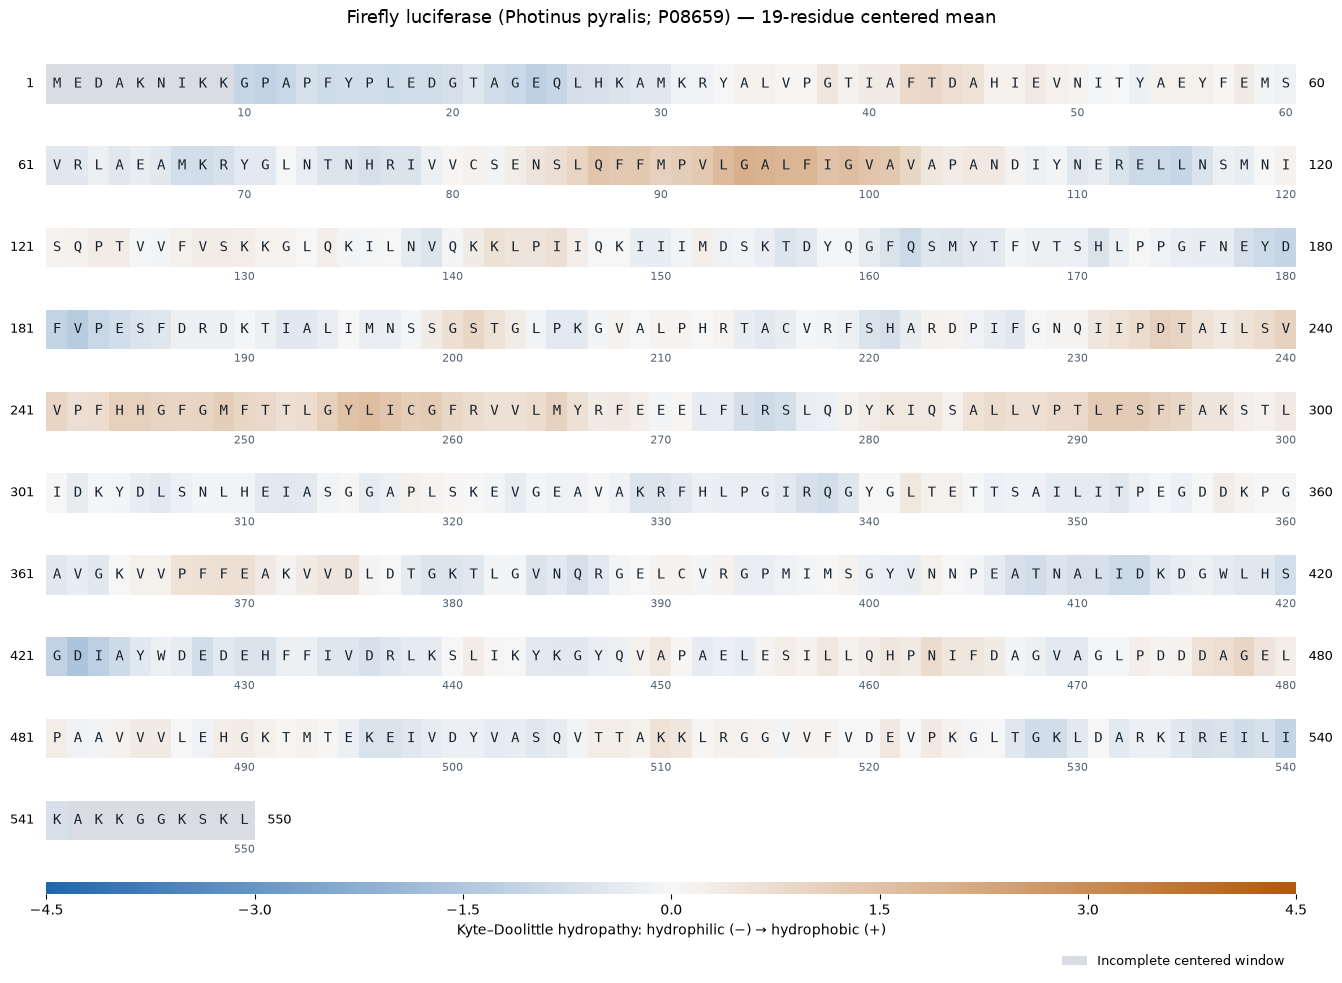

In [63]:
# Plot the 19-residue hydropathy profile for firefly luciferase.
fig, axes = plot_hydropathy(
    amino_acid_dict['P08659'],
    window=19,
    title='Firefly luciferase (Photinus pyralis; P08659)',
)
plt.show()


In [64]:
layer = 4
feature_id = 8893

esm_model = ESM(
    model_name="facebook/esm2_t6_8M_UR50D",
    device="cpu",
)

In [65]:
# Run every sequence through the same loaded model at layer 4.
# to obtain the embeddings for each protein - shape (number of residues, embedding dimension)
embeddings_by_protein = {
    accession: esm_model.embed_single_sequence(sequence, layer=layer)
    for accession, sequence in amino_acid_dict.items()
}

# Each residue has a 320-dimensional embedding.
for accession, embeddings in embeddings_by_protein.items():
    assert isinstance(embeddings, np.ndarray), f"{accession}: expected a NumPy array."
    expected_shape = (len(amino_acid_dict[accession]), 320)
    assert embeddings.shape == expected_shape, (
        f"{accession}: expected shape {expected_shape}, got {embeddings.shape}."
    )

In [66]:
# Load the pretrained SAE and switch to evaluation mode.
sae = load_sae_from_hf(
    plm_model="esm2-8m",
    plm_layer=layer,
)
sae = sae.to("cpu").eval()

Loading configs from /Users/ishanmitra/.cache/huggingface/hub/models--Elana--InterPLM-esm2-8m/snapshots/81d2429cd9dae7175f1dcd8b4c649a20cdc06c8c/layer_4/config.yaml
Loaded data type: <class 'interplm.train.configs.TrainingRunConfig'>
Data keys: Not a dict


In [67]:
# Reuse the loaded SAE to calculate every feature for each protein.
activations_by_protein = {}
with torch.inference_mode():
    for accession, embeddings in embeddings_by_protein.items():
        activations_by_protein[accession] = sae.encode_feat_subset(
            torch.as_tensor(embeddings, dtype=torch.float32),
            list(range(sae.dict_size)),
            normalize_features=True,
        ).cpu().numpy()

# One row per residue and one column per SAE feature.
for accession, activations in activations_by_protein.items():
    assert isinstance(activations, np.ndarray), f"{accession}: expected a NumPy array."
    expected_shape = (len(amino_acid_dict[accession]), sae.dict_size)
    assert activations.shape == expected_shape, (
        f"{accession}: expected shape {expected_shape}, got {activations.shape}."
    )

In [68]:
# Bind the data once so calls need only the accession and feature ID.
summarise_protein_activations = partial(
    summarise_activations,
    amino_acid_dict=amino_acid_dict,
    activations_by_protein=activations_by_protein,
)


In [69]:
# Print a feature summary for every protein, including the controls.
for accession in amino_acid_dict:
    summarise_protein_activations(accession, feature_id=feature_id)
    print()


P02786 — feature 8893; activation statistics ×100 (not percentages)
            Count   Mean     Q1  Median     Q3
Amino acid                                    
A              60 0.2920 0.0000  0.0000 0.0000
C               8 2.2305 0.0000  0.0000 3.1921
D              43 0.0183 0.0000  0.0000 0.0000
E              46 0.0000 0.0000  0.0000 0.0000
F              46 1.3138 0.0000  0.0000 0.0000
G              53 0.4636 0.0000  0.0000 0.0000
H              13 0.0000 0.0000  0.0000 0.0000
I              32 2.5250 0.0000  0.0000 0.0000
K              50 0.2788 0.0000  0.0000 0.0000
L              71 0.4272 0.0000  0.0000 0.0000
M              14 0.6721 0.0000  0.0000 0.0000
N              42 0.0856 0.0000  0.0000 0.0000
P              31 0.1368 0.0000  0.0000 0.0000
Q              23 0.0000 0.0000  0.0000 0.0000
R              33 0.1637 0.0000  0.0000 0.0000
S              56 0.2346 0.0000  0.0000 0.0000
T              44 0.5139 0.0000  0.0000 0.0000
V              56 0.7638 0.0000  0.0000

## Feature activation inside hydrophobic stretches

For this overlap analysis, define a **hydrophobic position as a window centre with H19 > 1.6**, using the same `calculate_hydropathy(sequence, window=19)` function above. The 1.6 value is a descriptive guide from [ExPASy ProtScale](https://web.expasy.org/protscale/protscale-doc.html), not proof of membrane insertion. This is a new analysis rule; it was not a hard cutoff for selecting the panel. Change `hydrophobic_threshold` in the next calculation cell to explore another cutoff.

Consecutive qualifying **centre positions** form the listed/shaded stretches. They are not expanded to cover every residue contributing to their 19-residue windows, and no additional minimum run length is imposed. A listed stretch can therefore be shorter than 19 residues. The first and last 9 positions have no complete window and are unscored; they are not classified as hydrophilic.

The new percentage is the fraction of **total feature activation** located at those hydrophobic positions:

$$
100\,\frac{\sum_{i:\,H_{19}(i)>1.6} A_i}{\sum_i A_i},
$$

where $A_i$ is the feature activation at residue $i$. Unscored ends contribute to the denominator but not the numerator. A zero-activation protein has an undefined percentage, shown as **—**. The previous membrane-overlap columns remain for comparison: they use UniProt **Transmembrane** intervals (full crossings, including OmpF's β-stranded intervals), excluding intramembrane sections and signal peptides. The plots now shade **hydrophobic stretches in green**. The amino-acid summaries above use the helper's ×100 scaling; this table and the plots use raw activation values.

Reference coordinates come from the [saved snapshot](data/reference/feature_8893_hydropathy_panel.json); the following cell checks sequence identity before using them.


In [70]:
# Load the same reference sequences and UniProt intervals used to select the panel.
panel_reference = json.loads(
    Path('data/reference/feature_8893_hydropathy_panel.json').read_text()
)
panel_proteins = {
    protein['primaryAccession']: protein
    for protein in panel_reference['proteins']
}
protein_names = {
    accession: protein['label']
    for accession, protein in panel_proteins.items()
}

if set(amino_acid_dict) != set(panel_proteins):
    raise ValueError('The loaded proteins must match the 15-protein reference panel.')
for accession, protein in panel_proteins.items():
    if amino_acid_dict[accession] != protein['sequence']['value']:
        raise ValueError(
            f'{accession}: downloaded sequence differs from the reference; '
            'check sequence versions and annotation coordinates before continuing.'
        )

# Keep full crossings, partial insertions and cleaved signals separate.
transmembrane_regions = {accession: [] for accession in protein_names}
intramembrane_regions = {accession: [] for accession in protein_names}
signal_peptide_regions = {accession: [] for accession in protein_names}
region_maps = {
    'Transmembrane': transmembrane_regions,
    'Intramembrane': intramembrane_regions,
    'Signal': signal_peptide_regions,
}
for accession, protein in panel_proteins.items():
    for feature in protein['reference_features']:
        if feature['type'] in region_maps:
            region = (
                feature['location']['start']['value'],
                feature['location']['end']['value'],
            )
            region_maps[feature['type']][accession].append(region)


In [71]:
# Define hydrophobic stretches from the notebook's existing 19-residue means.
hydrophobic_threshold = 1.6
hydropathy_profiles_by_protein = {}
hydrophobic_masks_by_protein = {}
hydrophobic_regions_by_protein = {}

for accession, sequence in amino_acid_dict.items():
    profile = calculate_hydropathy(sequence, window=19)
    scores = profile['window_mean'].to_numpy()
    # A tiny tolerance excludes exact cutoff ties despite floating-point rounding.
    # Terminal NaNs remain unscored and never enter the hydrophobic mask.
    hydrophobic_mask = np.isfinite(scores) & (scores > hydrophobic_threshold + 1e-12)
    hydropathy_profiles_by_protein[accession] = profile
    hydrophobic_masks_by_protein[accession] = hydrophobic_mask

    # Each False -> True / True -> False transition bounds one contiguous run.
    changes = np.diff(np.r_[False, hydrophobic_mask, False].astype(int))
    starts = np.flatnonzero(changes == 1) + 1
    ends = np.flatnonzero(changes == -1)
    hydrophobic_regions_by_protein[accession] = list(zip(starts.tolist(), ends.tolist()))


In [72]:
# Compare activation inside annotated membrane regions and calculated hydrophobic stretches.
overlap_rows = []
for accession, protein_name in protein_names.items():
    sequence = amino_acid_dict[accession]
    values = activations_by_protein[accession][:, feature_id].astype(np.float64)
    total = values.sum()
    regions = transmembrane_regions[accession]
    membrane_mask = np.zeros(len(sequence), dtype=bool)
    for start, end in regions:
        membrane_mask[start - 1:end] = True  # 1-based inclusive -> NumPy slice
    hydrophobic_mask = hydrophobic_masks_by_protein[accession]
    hydrophobic_regions = hydrophobic_regions_by_protein[accession]
    active = values > 0
    active_inside = membrane_mask & active

    overlap_rows.append({
        'Accession': accession,
        'Protein': protein_name,
        'Peak activation': values.max(),
        'Peak position': int(values.argmax() + 1) if total > 0 else None,
        'Nonzero residues': int(np.count_nonzero(active)),
        'Annotated membrane regions': ', '.join(f'{start}–{end}' for start, end in regions) or '—',
        'Activation inside membrane (%)': (
            100 * values[membrane_mask].sum() / total if total > 0 else np.nan
        ),
        'Hydrophobic stretches (H19 centres)': (
            ', '.join(f'{start}–{end}' for start, end in hydrophobic_regions) or '—'
        ),
        'Activation inside hydrophobic stretches (%)': (
            100 * values[hydrophobic_mask].sum() / total if total > 0 else np.nan
        ),
        'Active residues inside membrane': int(np.count_nonzero(active_inside)),
        'Active residues outside membrane': int(np.count_nonzero(~membrane_mask & active)),
        'Distinct amino acids active inside membrane': len(
            set(np.array(list(sequence))[active_inside])
        ),
    })

feature_8893_overlap = pd.DataFrame(overlap_rows).set_index('Accession')
display(feature_8893_overlap.style.format({
    'Peak activation': '{:.6f}',
    'Peak position': '{:.0f}',
    'Activation inside membrane (%)': '{:.2f}',
    'Activation inside hydrophobic stretches (%)': '{:.2f}',
    'Active residues inside membrane': '{:.0f}',
    'Active residues outside membrane': '{:.0f}',
    'Distinct amino acids active inside membrane': '{:.0f}',
}, na_rep='—'))


,Protein,Peak activation,Peak position,Nonzero residues,Annotated membrane regions,Activation inside membrane (%),Hydrophobic stretches (H19 centres),Activation inside hydrophobic stretches (%),Active residues inside membrane,Active residues outside membrane,Distinct amino acids active inside membrane
Accession,,,,,,,,,,,
P02786,TFRC,0.276743,75,44,68–88,74.76,70–83,71.35,18,26,9
P01732,CD8 alpha,0.774843,197,50,183–203,79.55,"10–11, 192–198",41.63,21,29,11
P0AEN4,FtsL,0.012595,47,1,35–57,100.00,40–51,100.00,1,0,1
P06821,M2,0.404102,36,43,23–43,82.80,"33–39, 41–42",54.59,21,22,10
P32867,Sso1,0.413075,274,25,266–287,96.32,270–281,77.21,20,5,8
P29972,AQP1,0.066603,222,17,"12–29, 47–65, 91–109, 134–153, 164–181, 207–224",61.87,"18–18, 20–27, 87–87, 90–91, 98–108, 111–111, 145–148, 175–175, 220–224",30.12,9,8,5
P02920,LacY,0.000000,—,0,"8–34, 42–70, 75–100, 105–129, 141–163, 167–186, 221–249, 254–278, 289–308, 312–334, 347–374, 378–398",—,"18–18, 20–25, 54–58, 83–92, 94–96, 99–101, 112–112, 152–156, 175–181, 300–300, 322–322, 324–325, 354–361, 385–394",—,0,0,0
P25874,UCP1,0.014527,299,4,"11–32, 74–96, 117–133, 179–195, 213–232, 267–289",15.07,21–23,0.00,2,2,1
P83755,D1 / PsbA,0.007363,119,1,"29–46, 118–133, 142–156, 197–218, 274–288",100.00,"39–47, 49–51, 151–152, 154–154, 281–282",0.00,1,0,1


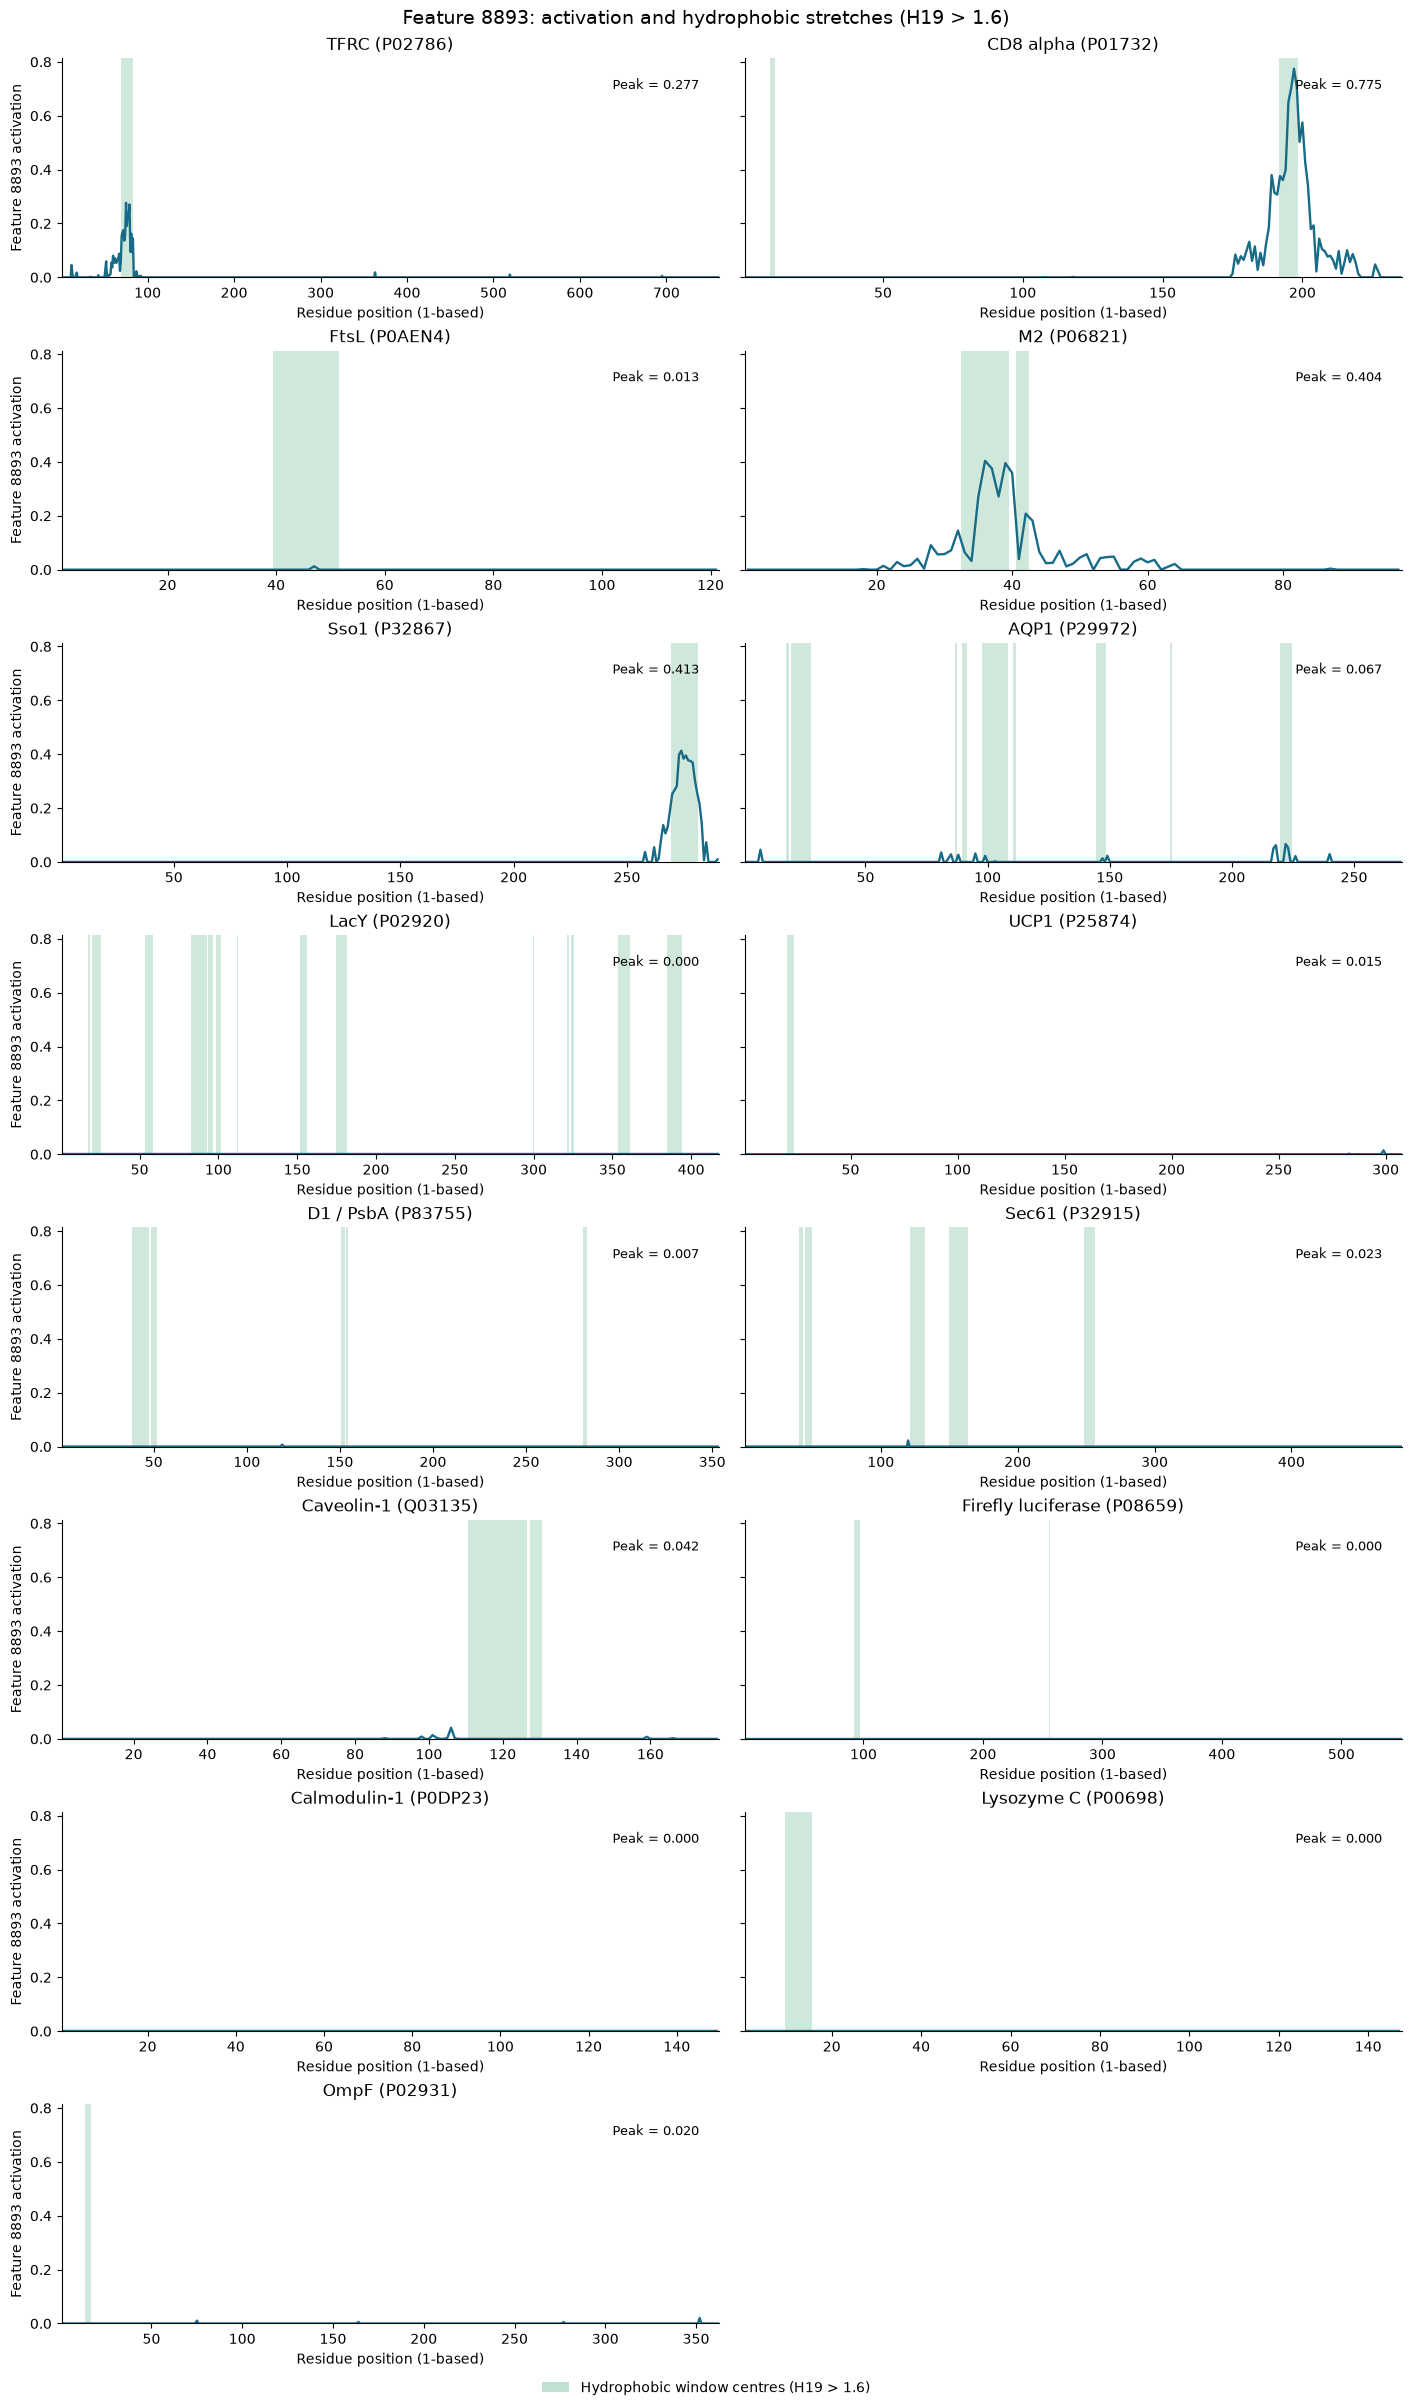

In [73]:
# Keep the shared activation scale; shade the same hydrophobic masks used in the table.
n_rows = (len(protein_names) + 1) // 2
fig, axes = plt.subplots(
    n_rows, 2, figsize=(14, 3 * n_rows), sharey=True, layout='constrained',
)

for ax, (accession, protein_name) in zip(axes.flat, protein_names.items()):
    sequence = amino_acid_dict[accession]
    values = activations_by_protein[accession][:, feature_id]
    ax.plot(np.arange(1, len(sequence) + 1), values, color='#176b87', lw=1.7)
    for start, end in hydrophobic_regions_by_protein[accession]:
        ax.axvspan(start - 0.5, end + 0.5, color='#66b68a', alpha=0.3, lw=0)
    ax.set(
        title=f'{protein_name} ({accession})',
        xlim=(0.5, len(sequence) + 0.5),
        xlabel='Residue position (1-based)',
    )
    ax.text(
        0.97, 0.91, f'Peak = {values.max():.3f}',
        ha='right', va='top', transform=ax.transAxes, fontsize=9,
    )
    ax.spines[['top', 'right']].set_visible(False)

# Set the common lower bound after every trace has contributed to autoscaling.
axes[0, 0].set_ylim(bottom=0)

# Fifteen proteins leave one unused panel in the two-column grid.
for ax in axes.flat[len(protein_names):]:
    ax.set_visible(False)
for ax in axes[:, 0]:
    ax.set_ylabel(f'Feature {feature_id} activation')

fig.suptitle(
    f'Feature {feature_id}: activation and hydrophobic stretches (H19 > {hydrophobic_threshold:g})',
    fontsize=14,
)
fig.legend(
    handles=[
        Patch(
            facecolor='#66b68a', alpha=0.4,
            label=f'Hydrophobic window centres (H19 > {hydrophobic_threshold:g})',
        ),
    ],
    loc='outside lower center', frameon=False,
)
plt.show()


In [75]:
# note unscored H19 - could not calculate a 19 residue window at that position
# the first and last residues cannot have a H19 score

In [76]:
# Pool raw feature activation across every protein in the panel.
# Percentages are shares of this pooled total, not averages of protein percentages.
# The requested region totals overlap; the contingency-table cells are disjoint.
hydropathy_classes = ['Hydrophobic', 'Scored at/below cutoff', 'Unscored H19']
membrane_classes = ['TM only', 'IM only', 'Both TM and IM', 'Neither TM nor IM']
activation_cross_tab = pd.DataFrame(
    0.0, index=hydropathy_classes, columns=membrane_classes,
)
residue_cross_tab = pd.DataFrame(
    0, index=hydropathy_classes, columns=membrane_classes,
)
region_totals = {}
total_activation = 0.0
total_residues = 0

for accession, sequence in amino_acid_dict.items():
    values = activations_by_protein[accession][:, feature_id].astype(np.float64)
    if not np.isfinite(values).all() or np.any(values < 0):
        raise ValueError(f'{accession}: expected finite, nonnegative SAE activations.')
    scores = hydropathy_profiles_by_protein[accession]['window_mean'].to_numpy()
    scored = np.isfinite(scores)
    hydrophobic = hydrophobic_masks_by_protein[accession]
    below_cutoff = scored & ~hydrophobic
    unscored = ~scored

    tm = np.zeros(len(sequence), dtype=bool)
    im = np.zeros(len(sequence), dtype=bool)
    for start, end in transmembrane_regions[accession]:
        tm[start - 1:end] = True  # 1-based inclusive coordinates
    for start, end in intramembrane_regions[accession]:
        im[start - 1:end] = True
    membrane_union = tm | im

    # These are marginal/intersection totals: they intentionally overlap.
    # "Not marked hydrophobic" includes unscored ends, so also print its breakdown.
    requested_masks = {
        'Hydrophobic, anywhere': hydrophobic,
        'Transmembrane (TM)': tm,
        'Intramembrane (IM)': im,
        'TM + IM (union)': membrane_union,
        'Hydrophobic AND TM': hydrophobic & tm,
        'Hydrophobic AND IM': hydrophobic & im,
        'Hydrophobic AND (TM + IM)': hydrophobic & membrane_union,
        'Neither marked hydrophobic nor TM (incl. unscored)': ~hydrophobic & ~tm,
        '  Scored at/below cutoff AND outside TM': below_cutoff & ~tm,
        '  Unscored H19 AND outside TM': unscored & ~tm,
        'Hydrophobic AND outside TM': hydrophobic & ~tm,
        'Hydrophobic AND outside IM': hydrophobic & ~im,
        'Hydrophobic AND outside both TM and IM': hydrophobic & ~membrane_union,
        'Scored at/below cutoff AND TM': below_cutoff & tm,
        'Scored at/below cutoff AND IM': below_cutoff & im,
        'Scored at/below cutoff AND (TM + IM)': below_cutoff & membrane_union,
        'Scored at/below cutoff AND outside both TM and IM': below_cutoff & ~membrane_union,
        'Unscored H19, anywhere': unscored,
    }
    for label, mask in requested_masks.items():
        totals = region_totals.setdefault(label, {'Activation sum': 0.0, 'Residues': 0})
        totals['Activation sum'] += float(values[mask].sum())
        totals['Residues'] += int(mask.sum())

    # Cross hydrophobic status with the two independent TM/IM annotation flags.
    hydro_masks = [hydrophobic, below_cutoff, unscored]
    membrane_masks = [tm & ~im, im & ~tm, tm & im, ~membrane_union]
    for row, hydro_mask in zip(hydropathy_classes, hydro_masks):
        for column, membrane_mask in zip(membrane_classes, membrane_masks):
            cell_mask = hydro_mask & membrane_mask
            activation_cross_tab.loc[row, column] += float(values[cell_mask].sum())
            residue_cross_tab.loc[row, column] += int(cell_mask.sum())
    total_activation += float(values.sum())
    total_residues += len(sequence)

# Check that every residue and every unit of activation enters exactly one cell.
assert residue_cross_tab.to_numpy().sum() == total_residues
assert np.isclose(activation_cross_tab.to_numpy().sum(), total_activation)
activation_cross_tab_percent = (
    100 * activation_cross_tab / total_activation
    if total_activation > 0 else activation_cross_tab * np.nan
)
activation_region_summary = pd.DataFrame.from_dict(region_totals, orient='index')
activation_region_summary.index.name = 'Region / condition'
activation_region_summary.insert(
    1, '% of total activation',
    100 * activation_region_summary['Activation sum'] / total_activation
    if total_activation > 0 else np.nan,
)

print(f'Feature {feature_id} — pooled across {len(amino_acid_dict)} proteins')
print(f'Hydrophobic: H19 > {hydrophobic_threshold:g}; first/last 9 residues are unscored.')
print(f'Total raw activation: {total_activation:.6f}; total residues: {total_residues}')
print('Percentages use all activation, including unscored ends. Overlapping rows do not sum to 100%.')
print('\nRequested totals and additional combinations:')
print(activation_region_summary.to_string(
    formatters={
        'Activation sum': lambda value: f'{value:.6f}',
        '% of total activation': lambda value: f'{value:.2f}',
    },
    na_rep='—',
))

# Add row/column margins only for display; keep the 3 × 4 numeric tables above.
activation_cross_tab_with_totals = activation_cross_tab.copy()
activation_cross_tab_with_totals['Total'] = activation_cross_tab.sum(axis=1)
activation_cross_tab_with_totals.loc['Total'] = activation_cross_tab_with_totals.sum(axis=0)


def format_activation_cell(value):
    percentage = 100 * value / total_activation if total_activation > 0 else np.nan
    share = f'{percentage:.2f}%' if np.isfinite(percentage) else '—'
    return f'{value:.6f} ({share})'


print('\nActivation-weighted contingency table: raw sum (% of all activation)')
print('Only the 12 interior cells partition the total; row/column margins are summaries.')
print(activation_cross_tab_with_totals.map(format_activation_cell).to_string())
# Numeric results remain available as activation_cross_tab,
# activation_cross_tab_percent, residue_cross_tab and activation_region_summary.


Feature 8893 — pooled across 15 proteins
Hydrophobic: H19 > 1.6; first/last 9 residues are unscored.
Total raw activation: 22.802035; total residues: 4715
Percentages use all activation, including unscored ends. Overlapping rows do not sum to 100%.

Requested totals and additional combinations:
                                                   Activation sum % of total activation  Residues
Region / condition                                                                               
Hydrophobic, anywhere                                   12.770885                 56.01       248
Transmembrane (TM)                                      18.784160                 82.38      1110
Intramembrane (IM)                                       0.082711                  0.36        48
TM + IM (union)                                         18.866871                 82.74      1158
Hydrophobic AND TM                                      12.770885                 56.01       204
Hydrophobic AND IM